# Project 1: Telco Customer Churn Prediction
**Professional Training in AI 1**

This notebook covers Stages 1 to 4 (data description, preprocessing and analysis, modeling and tuning, evaluation).
Stage 5 (deployment) is in `app.py`, `model.pkl` and `requirements.txt`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Stage 1: Data description

**Source.** The *Telco Customer Churn* dataset (IBM sample data, published on Kaggle:
https://www.kaggle.com/datasets/blastchar/telco-customer-churn). It describes a fictional telecom company that provides
home phone and internet services to customers in California.

**Problem.** Acquiring a new customer costs much more than keeping an existing one. If we can predict which customers are
likely to **churn** (cancel their service), the company can target them with retention offers. We build a model that predicts
churn from a customer's account and service information.

**Task type.** Supervised **binary classification**. The target is `Churn` (Yes / No).

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Feature dictionary

| Column | Meaning | Type |
|---|---|---|
| customerID | Unique customer identifier | ID (text) |
| gender | Male / Female | Categorical |
| SeniorCitizen | 1 if the customer is a senior citizen, else 0 | Binary (numeric) |
| Partner | Whether the customer has a partner | Categorical (Yes/No) |
| Dependents | Whether the customer has dependents | Categorical (Yes/No) |
| tenure | Number of months the customer has stayed with the company | Numeric |
| PhoneService | Whether the customer has phone service | Categorical (Yes/No) |
| MultipleLines | Whether the customer has multiple phone lines | Categorical |
| InternetService | Internet provider type (DSL, Fiber optic, No) | Categorical |
| OnlineSecurity | Online security add-on | Categorical |
| OnlineBackup | Online backup add-on | Categorical |
| DeviceProtection | Device protection add-on | Categorical |
| TechSupport | Tech support add-on | Categorical |
| StreamingTV | Streams TV | Categorical |
| StreamingMovies | Streams movies | Categorical |
| Contract | Month-to-month, One year, Two year | Categorical |
| PaperlessBilling | Whether billing is paperless | Categorical (Yes/No) |
| PaymentMethod | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) | Categorical |
| MonthlyCharges | Amount charged each month | Numeric |
| TotalCharges | Total amount charged over the customer's lifetime | Numeric (stored as text) |
| **Churn** | **Whether the customer left (target)** | **Categorical (Yes/No)** |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Numeric summary statistics")
display(df.describe())
print("Categorical summary statistics")
display(df.describe(include="object").T)

Numeric summary statistics


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Categorical summary statistics


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


**Observations.**
- 7,043 customers and 21 columns: 1 ID, 19 features and 1 target.
- `TotalCharges` is stored as text (`object`) even though it should be numeric. This is a data quality issue we fix in Stage 2.
- `SeniorCitizen` is already 0/1, while all other binary columns use Yes/No.
- `tenure` ranges from 0 to 72 months and `MonthlyCharges` from about 18 to 119.

# Stage 2: Preprocessing and analysis

## 2.1 Missing values, duplicates and inconsistent entries

In [5]:
print("Missing values (NaN) per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "None: no NaN values at the moment")

Missing values (NaN) per column:
None: no NaN values at the moment


`isna()` finds no missing values, but `TotalCharges` is text, which hints at hidden problems such as blank strings.
We convert it to numeric; anything that cannot be parsed becomes `NaN`.

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


**Decision.** All 11 rows with a blank `TotalCharges` have `tenure = 0`: they are brand-new customers who have not been
billed yet, so their total charges are genuinely **0**. We fill them with 0 (a rule based on business logic, not on dataset
statistics, so it cannot leak information from the test set) rather than dropping 11 valid customers.

In [7]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Duplicates (ignoring the unique ID, which would make every row different)
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())
print("Duplicate rows (excluding ID):", df.drop(columns="customerID").duplicated().sum())

Duplicate customerIDs: 0
Duplicate rows (excluding ID): 22


There are no duplicate customer IDs, so no customer appears twice.
Some rows are identical when the ID is ignored, but with only 19 mostly categorical features, different customers can legitimately
share the same profile, so these are **not true duplicates** and we keep them.

In [8]:
cat_cols_all = df.select_dtypes(include="object").columns.drop(["customerID"])
for c in cat_cols_all:
    print(f"{c:18s}", df[c].value_counts().to_dict())

gender             {'Male': 3555, 'Female': 3488}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit 

**Inconsistent entries.** No typos, casing or whitespace problems were found. There is, however, a redundancy:
the add-on columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`)
contain the value **"No internet service"**, and `MultipleLines` contains **"No phone service"**. These are fully determined by
`InternetService = No` / `PhoneService = No`, so they are the same information as a plain "No". We merge them into "No" to
reduce the number of categories (and later the number of one-hot columns). Also, `SeniorCitizen` is 0/1 while other binary columns
are Yes/No, so we convert it to Yes/No for consistency.

In [9]:
df = df.replace({"No internet service": "No", "No phone service": "No"})
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # numeric target: 1 = churned

# sanity checks for impossible values
print("Negative tenure:", (df.tenure < 0).sum(), "| Negative charges:", (df.MonthlyCharges < 0).sum())
print(df["OnlineSecurity"].value_counts().to_dict())

Negative tenure: 0 | Negative charges: 0
{'No': 5024, 'Yes': 2019}


## 2.2 Outliers

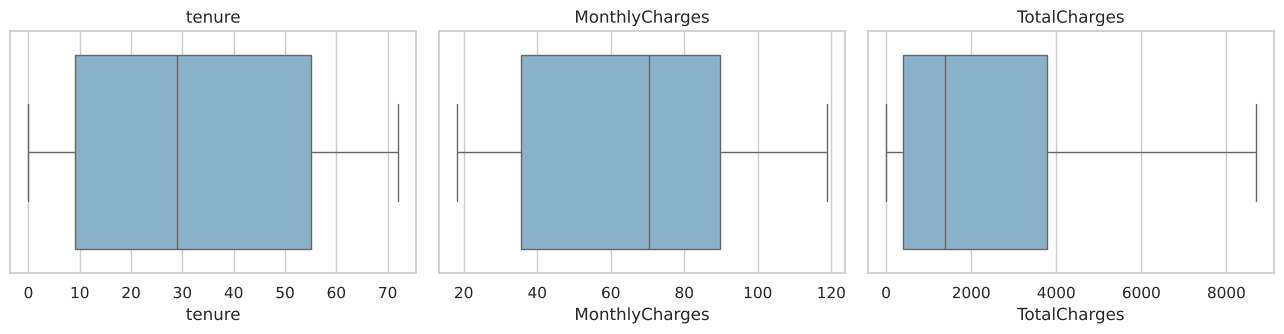

tenure          IQR outliers: 0
MonthlyCharges  IQR outliers: 0
TotalCharges    IQR outliers: 0


In [10]:
num_cols_all = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, num_cols_all):
    sns.boxplot(x=df[c], ax=ax, color="#7fb3d5"); ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols_all:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c:15s} IQR outliers: {n}")

**Decision.** The IQR rule flags **no outliers** in `tenure` and `MonthlyCharges`. `TotalCharges` is right-skewed
(long-tenure customers with high plans naturally accumulate large totals), but those values are real and consistent with
`tenure x MonthlyCharges`, not errors. Nothing needs to be removed or capped. Also, tree-based models (our final choice) are robust
to such skew, and the numeric features are standardized in the pipeline.

## 2.3 Exploratory data analysis

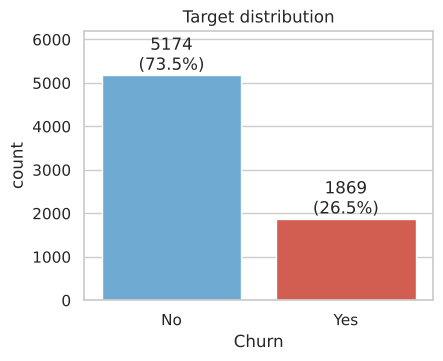

In [11]:
# 1) Target distribution
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x="Churn", data=df, ax=ax, palette=["#5dade2", "#e74c3c"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df):.1%})", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_ylim(0, 6200); ax.set_title("Target distribution"); plt.show()

**Class imbalance.** About 73.5% of customers stayed and 26.5% churned. The data is moderately imbalanced, so plain accuracy
would be misleading (always predicting "No" gives ~73.5%). We will (a) split with `stratify`, (b) tune with **F1** instead of
accuracy, and (c) try `class_weight="balanced"` in the grid search.

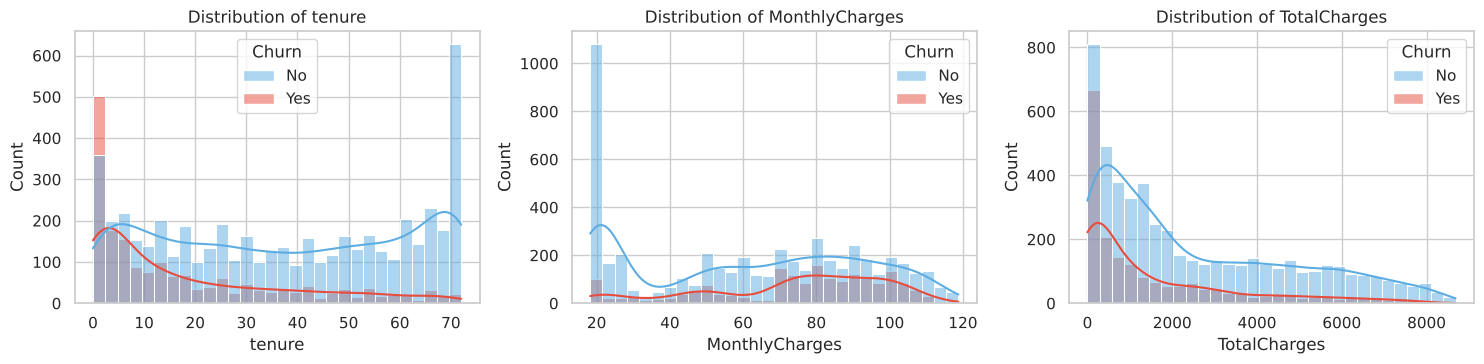

In [12]:
# 2) Distributions of numeric features, split by churn
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, num_cols_all):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, bins=30, ax=ax, palette=["#5dade2", "#e74c3c"])
    ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

- **tenure:** churners are concentrated in the first months, while loyal customers pile up at 70+ months. New customers are the most at risk.
- **MonthlyCharges:** churners skew toward higher monthly bills (about 70 to 100).
- **TotalCharges:** strongly right-skewed. Churners have low totals mostly because they leave early.

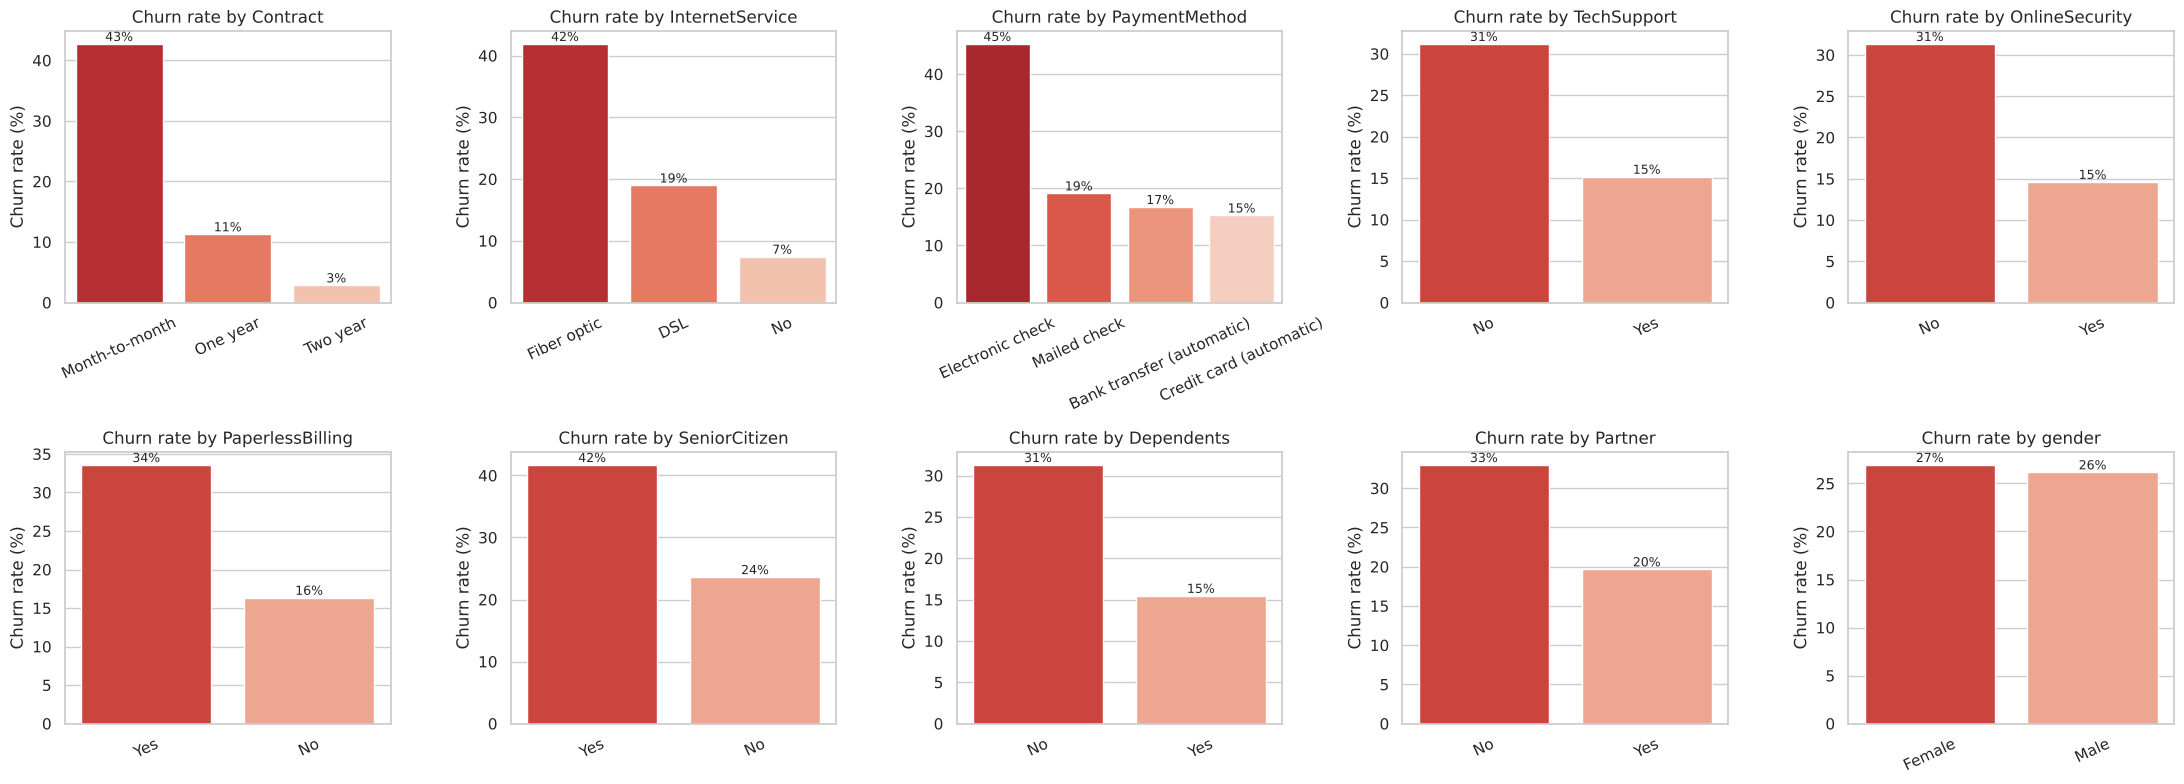

In [13]:
# 3) Categorical features vs. churn rate
cats_plot = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling",
             "SeniorCitizen", "Dependents", "Partner", "gender"]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.ravel(), cats_plot):
    rate = df.groupby(c)["ChurnFlag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="Reds_r")
    ax.set_title(f"Churn rate by {c}"); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

Findings:
- **Contract** is the strongest driver: month-to-month customers churn at ~43%, versus ~11% (one year) and ~3% (two year).
- **InternetService:** Fiber optic customers churn far more (~42%) than DSL (~19%) or no internet (~7%).
- **PaymentMethod:** electronic-check payers churn most (~45%); automatic payment methods are around 15 to 17%.
- **TechSupport / OnlineSecurity:** customers *without* these add-ons churn about 2 to 3 times more.
- **SeniorCitizen** and **PaperlessBilling** show moderately higher churn; **Dependents** moderately lower; **gender** shows essentially no difference.

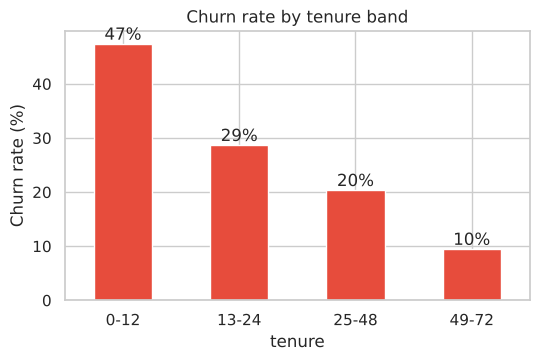

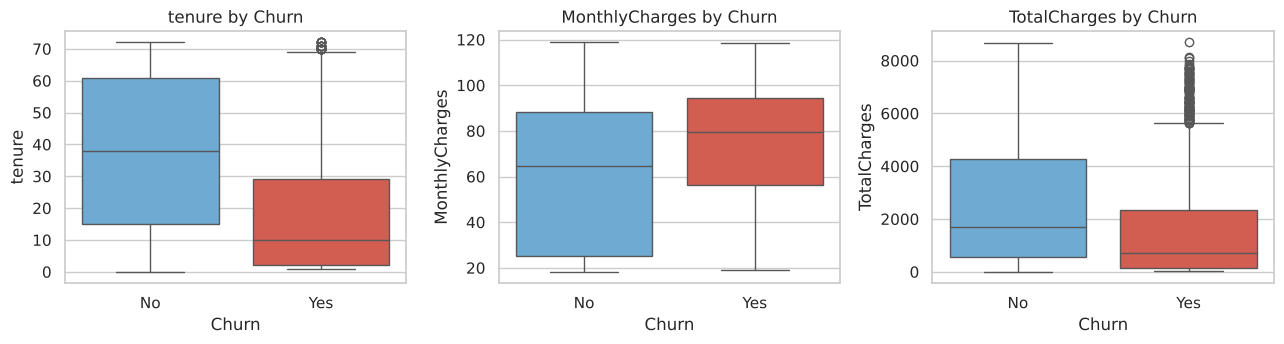

In [14]:
# 4) Tenure bands and churn
bands = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
rate = df.groupby(bands)["ChurnFlag"].mean() * 100
ax = rate.plot(kind="bar", color="#e74c3c", figsize=(6, 3.5), rot=0)
ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate by tenure band")
for p in ax.patches: ax.annotate(f"{p.get_height():.0f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.show()

# 5) Numeric features vs. target
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, num_cols_all):
    sns.boxplot(x="Churn", y=c, data=df, ax=ax, palette=["#5dade2", "#e74c3c"])
    ax.set_title(f"{c} by Churn")
plt.tight_layout(); plt.show()

Churn falls steadily as tenure grows (about 48% in the first year versus about 9% after 4 years), and churners have a much lower median tenure and slightly higher monthly charges.

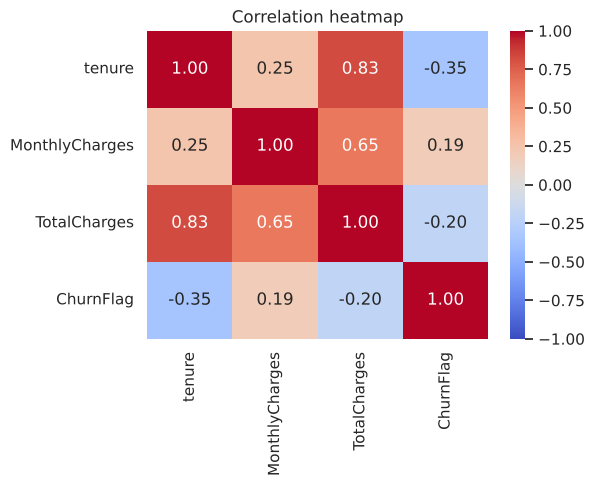

In [15]:
# 6) Correlation heatmap (numeric features + target)
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]].corr()
plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f"); plt.title("Correlation heatmap"); plt.show()

`tenure` and `TotalCharges` are strongly correlated (0.83), and `TotalCharges` is also correlated with `MonthlyCharges` (0.65).
`TotalCharges` is essentially `tenure x MonthlyCharges`, so it is redundant. `tenure` has the strongest negative correlation with churn (about -0.35).

## 2.4 Train/test split (before any statistics-based step)
To avoid **data leakage**, we split first and then fit anything that learns from the data (feature selection, imputers, scalers, encoders)
on the **training set only**. We use an 80/20 split with `stratify=y`, so both parts keep the same ~26.5% churn rate.

In [16]:
X = df.drop(columns=["customerID", "Churn", "ChurnFlag"])
y = df["ChurnFlag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.265 | test: 0.265


## 2.5 Feature engineering and feature selection
- **`customerID`** is an identifier with no predictive value and was dropped above.
- **`TotalCharges`** is dropped because it is redundant with `tenure x MonthlyCharges` (correlation 0.83 with tenure), and keeping it adds
  multicollinearity without new information.
- For the rest, we rank features by **mutual information** with the target, computed on the **training set only** (so the test set cannot
  influence which features are kept). We then check, with cross-validation on the training set, whether a larger feature set actually helps.

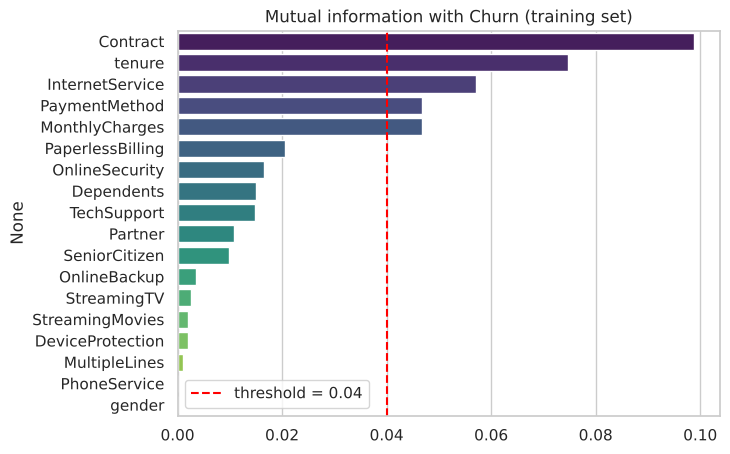

Contract            0.0989
tenure              0.0746
InternetService     0.0570
PaymentMethod       0.0469
MonthlyCharges      0.0468
PaperlessBilling    0.0205
OnlineSecurity      0.0165
Dependents          0.0151
TechSupport         0.0148
Partner             0.0107
SeniorCitizen       0.0099
OnlineBackup        0.0035
StreamingTV         0.0026
StreamingMovies     0.0020
DeviceProtection    0.0019
MultipleLines       0.0010
PhoneService        0.0002
gender              0.0000
dtype: float64

In [17]:
X_mi = X_train.drop(columns="TotalCharges").copy()
cat_mi = X_mi.select_dtypes(include="object").columns.tolist()
for c in cat_mi:
    X_mi[c] = X_mi[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(X_mi, y_train, discrete_features=[c in cat_mi for c in X_mi.columns],
                                   random_state=RANDOM_STATE), index=X_mi.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5)); sns.barplot(x=mi.values, y=mi.index, palette="viridis")
plt.axvline(0.04, color="red", ls="--", label="threshold = 0.04"); plt.legend(); plt.title("Mutual information with Churn (training set)")
plt.show()
mi.round(4)

In [18]:
def make_prep(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])

candidates = {
    "5 features (MI >= 0.04)":  mi[mi >= 0.04].index.tolist(),
    "9 features (MI >= 0.014)": mi[mi >= 0.014].index.tolist(),
}
cv_sel = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, feats in candidates.items():
    nc = [c for c in feats if c in ["tenure", "MonthlyCharges"]]; cc = [c for c in feats if c not in nc]
    p = Pipeline([("prep", make_prep(nc, cc)),
                  ("model", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=10,
                                                   class_weight="balanced", random_state=RANDOM_STATE))])
    sc = cross_val_score(p, X_train[feats], y_train, cv=cv_sel, scoring="f1")
    print(f"{name:26s} CV F1 = {sc.mean():.4f} (+/- {sc.std():.4f})  ->  {feats}")

5 features (MI >= 0.04)    CV F1 = 0.6308 (+/- 0.0132)  ->  ['Contract', 'tenure', 'InternetService', 'PaymentMethod', 'MonthlyCharges']


9 features (MI >= 0.014)   CV F1 = 0.6302 (+/- 0.0153)  ->  ['Contract', 'tenure', 'InternetService', 'PaymentMethod', 'MonthlyCharges', 'PaperlessBilling', 'OnlineSecurity', 'Dependents', 'TechSupport']


Adding `PaperlessBilling`, `OnlineSecurity`, `Dependents` and `TechSupport` does **not** improve the cross-validated F1 (0.630 versus 0.631), so we choose the
**simpler 5-feature set**: fewer inputs, less overfitting risk, and an easier app for end users. This is consistent with the EDA: after we merged
"No internet service" into "No", the add-on columns (security, backup, protection, tech support, streaming) mostly repeat what `InternetService` and
`Contract` already say, and `gender`, `PhoneService` and `MultipleLines` carry almost no information (mutual information close to 0).

In [19]:
selected = candidates["5 features (MI >= 0.04)"]
num_cols = [c for c in selected if c in ["tenure", "MonthlyCharges"]]
cat_cols = [c for c in selected if c not in num_cols]
print("Selected features:", selected)
print("Numeric:", num_cols); print("Categorical:", cat_cols)

X_train_s, X_test_s = X_train[selected], X_test[selected]

Selected features: ['Contract', 'tenure', 'InternetService', 'PaymentMethod', 'MonthlyCharges']
Numeric: ['tenure', 'MonthlyCharges']
Categorical: ['Contract', 'InternetService', 'PaymentMethod']


## 2.6 Encoding and scaling
A `ColumnTransformer` inside a `Pipeline` handles everything and is fit **only on the training data**:
- **Numeric** (`tenure`, `MonthlyCharges`): median imputation (safe fallback) then `StandardScaler`.
- **Categorical**: most-frequent imputation (safe fallback) then **One-Hot Encoding** (`handle_unknown="ignore"`), since none of the categories has a natural order.

In [20]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
Xt = preprocessor.fit_transform(X_train_s)
print("Transformed training matrix:", Xt.shape)

Transformed training matrix: (5634, 12)


# Stage 3: Modeling and tuning

**Model choice: Random Forest.** The data is tabular with a mix of numeric and one-hot categorical features, and the churn patterns are
non-linear and involve interactions (for example, fiber optic *and* month-to-month *and* low tenure is much riskier than any of them alone).
Random Forests capture such interactions automatically, need little feature engineering, are robust to skew and outliers, resist overfitting
better than a single tree, and support `class_weight` for the imbalance. As a sanity check, we first train a simple **Logistic Regression baseline**.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
base_f1 = cross_val_score(baseline, X_train_s, y_train, cv=cv, scoring="f1")
print(f"Baseline Logistic Regression  CV F1 = {base_f1.mean():.4f} (+/- {base_f1.std():.4f})")

Baseline Logistic Regression  CV F1 = 0.6236 (+/- 0.0179)


In [22]:
pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"],
}
n_combos = np.prod([len(v) for v in param_grid.values()])
print(f"Grid: {n_combos} combinations x 5 folds = {n_combos*5} fits")
for k, v in param_grid.items(): print(f"  {k}: {v}")

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True)
grid.fit(X_train_s, y_train)

Grid: 72 combinations x 5 folds = 360 fits
  model__n_estimators: [100, 200, 300]
  model__max_depth: [5, 8, 12, None]
  model__min_samples_leaf: [1, 5, 10]
  model__class_weight: [None, 'balanced']


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [5, 8, ...], 'model__min_samples_leaf': [1, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`

In [23]:
print("Best parameters:", grid.best_params_)
print(f"Best cross-validation F1: {grid.best_score_:.4f}")
print(f"Baseline (Logistic Regression) CV F1: {base_f1.mean():.4f}")

res = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
res[["rank_test_score", "mean_test_score", "mean_train_score", "param_model__n_estimators", "param_model__max_depth",
     "param_model__min_samples_leaf", "param_model__class_weight"]].head(8)

Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}
Best cross-validation F1: 0.6308
Baseline (Logistic Regression) CV F1: 0.6236


,rank_test_score,mean_test_score,mean_train_score,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,param_model__class_weight
52,1,0.630762,0.659446,200,8,10,balanced
53,2,0.630316,0.658658,300,8,10,balanced
50,3,0.629570,0.669732,300,8,5,balanced
48,4,0.629410,0.670396,100,8,5,balanced
51,5,0.629337,0.659793,100,8,10,balanced
60,6,0.629178,0.678123,100,12,10,balanced
37,7,0.628736,0.638912,200,5,1,balanced
36,8,0.628434,0.639584,100,5,1,balanced


# Stage 4: Evaluation on the test set

In [24]:
best = grid.best_estimator_
y_pred = best.predict(X_test_s)
y_proba = best.predict_proba(X_test_s)[:, 1]
y_pred_tr = best.predict(X_train_s)

metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1":        f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_proba),
}
train_metrics = {
    "Accuracy":  accuracy_score(y_train, y_pred_tr),
    "Precision": precision_score(y_train, y_pred_tr),
    "Recall":    recall_score(y_train, y_pred_tr),
    "F1":        f1_score(y_train, y_pred_tr),
    "ROC-AUC":   roc_auc_score(y_train, best.predict_proba(X_train_s)[:, 1]),
}
comp = pd.DataFrame({"Train": train_metrics, "Test": metrics}).round(4)
display(comp)
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

,Train,Test
Accuracy,0.7710,0.7544
Precision,0.5452,0.5254
Recall,0.8274,0.7754
F1,0.6573,0.6263
ROC-AUC,0.8742,0.8393


              precision    recall  f1-score   support

      Stayed       0.90      0.75      0.82      1035
     Churned       0.53      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



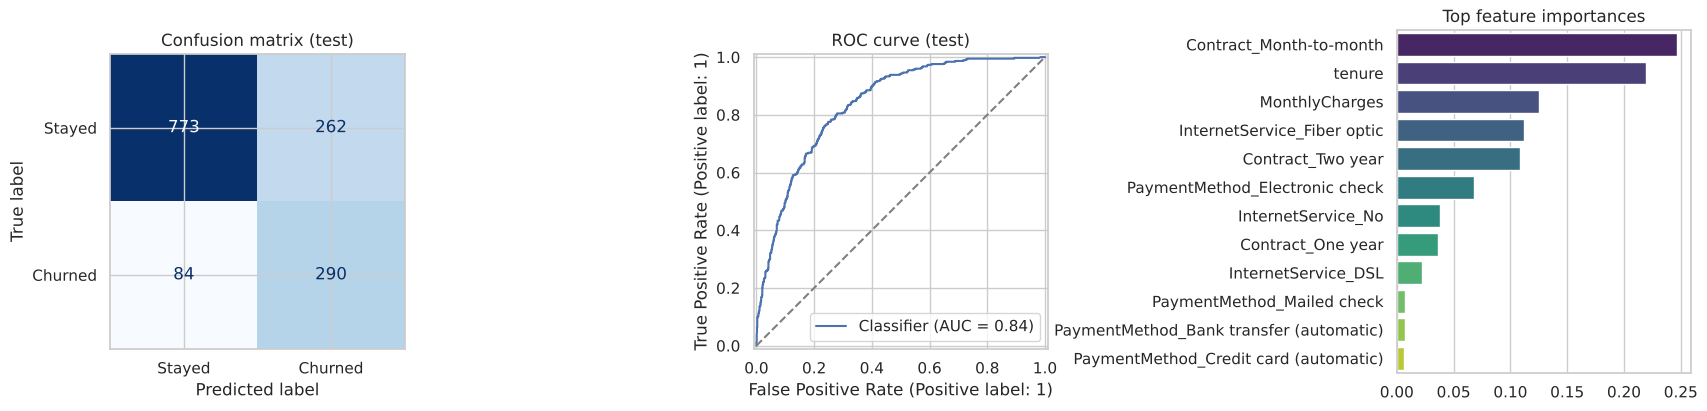

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stayed", "Churned"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "--", color="gray"); axes[1].set_title("ROC curve (test)")

ohe_names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=ohe_names).sort_values(ascending=False).head(12)
sns.barplot(x=imp.values, y=[n.split("__")[1] for n in imp.index], ax=axes[2], palette="viridis"); axes[2].set_title("Top feature importances")
plt.tight_layout(); plt.show()

### Evaluation summary

**Overall performance.** On the held-out test set (1,409 customers) the tuned Random Forest reaches an **accuracy of 75.4%**, **recall of 77.5%**,
**precision of 52.5%**, **F1 of 0.63** and a **ROC-AUC of 0.84**. The confusion matrix shows 290 churners correctly caught and 84 missed
(out of 374), with 262 loyal customers wrongly flagged as churners and 773 correctly identified as staying. The accuracy looks modest because we deliberately
used `class_weight="balanced"` and F1 for tuning: the model prefers to catch churners (high recall) at the cost of more false alarms (lower precision).
For a retention campaign this is a sensible trade-off, since missing a churner (losing the customer) is usually more costly than offering a discount to someone who would have stayed.
The model also beats the Logistic Regression baseline (CV F1 0.631 versus 0.624), but only slightly, which suggests the signal in these few features is largely
simple and close to linear, and that the remaining errors come from information the dataset does not contain (for example, service quality or competitor offers).

**Where it struggles.**
- *Precision on the churn class is low (about 0.53).* Almost all false positives (257 of 262) are **month-to-month customers**: this group churns at ~43%, so the model
  flags many of them, and more than half of those flagged do not actually leave.
- *Customers on one-year and two-year contracts are rarely flagged as churners.* The model catches only about 11% of the churners with a one-year contract and none with a two-year contract, because
  there are very few of them (these customers churn at ~11% and ~3%) and no feature clearly separates them.

**Overfitting.** The signs of overfitting are mild. Train versus test: F1 0.657 versus 0.626, accuracy 0.771 versus 0.754 and ROC-AUC 0.874 versus 0.839, a small, expected gap.
The cross-validation F1 (0.631) is also very close to the test F1 (0.626), so the CV estimate was reliable and the model generalizes. The regularization chosen by the grid search
(`max_depth=8`, `min_samples_leaf=10`) helped keep the trees from memorizing the training data.

**Most important features.** Contract type (month-to-month and two-year), `tenure`, `MonthlyCharges`, fiber-optic internet and electronic-check payment are the top drivers,
which matches the patterns found in the EDA.

# Stage 5: Save the model and preprocessing objects
We save the **full pipeline** (preprocessing + tuned model) as `model.pkl`, the fitted preprocessor on its own as `preprocessor.pkl`,
and the metadata the app needs (feature names, category options, numeric ranges) as `metadata.pkl`.

In [26]:
pickle.dump(best, open("model.pkl", "wb"))
pickle.dump(best.named_steps["prep"], open("preprocessor.pkl", "wb"))

metadata = {
    "features": selected,
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "cat_options": {c: sorted(X_train_s[c].unique().tolist()) for c in cat_cols},
    "num_ranges": {c: (float(X_train_s[c].min()), float(X_train_s[c].max()), float(X_train_s[c].median())) for c in num_cols},
    "metrics": {k: round(v, 4) for k, v in metrics.items()},
    "best_params": {k.replace("model__", ""): v for k, v in grid.best_params_.items()},
}
pickle.dump(metadata, open("metadata.pkl", "wb"))

# round-trip check: the reloaded pipeline gives identical predictions
reloaded = pickle.load(open("model.pkl", "rb"))
assert (reloaded.predict(X_test_s) == y_pred).all()
print("Saved model.pkl, preprocessor.pkl, metadata.pkl and verified reload.")
import sklearn; print("scikit-learn version used for training:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)

Saved model.pkl, preprocessor.pkl, metadata.pkl and verified reload.
scikit-learn version used for training: 1.9.1 | pandas: 3.0.6 | numpy: 2.5.4
